# Bài 22 — Experiment 5: Sequence length

So sánh các độ dài chuỗi `32`, `64`, `128`, `256` trên cùng mô hình Transformer phân loại IMDb. Theo dõi số token được giữ lại, kích thước attention matrix lý thuyết, thời gian huấn luyện và F1 trên test. Cố định vocabulary, cách chia dữ liệu, kiến trúc, batch size, optimizer, learning rate và số epoch.

Nhãn: `0 = negative`, `1 = positive`.

In [ ]:
import os, random, tarfile, time, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)
print('TensorFlow:', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))


TensorFlow: 2.21.0
GPU: []


## 1. Nạp dữ liệu IMDb

Ưu tiên ACL IMDb raw của Stanford. Nếu kết nối bị từ chối, notebook chuyển sang bản IMDb của Keras. Validation được tách stratified từ tập train; test chỉ dùng ở bước đánh giá cuối.


In [ ]:
DATA_DIR = Path('/content/aclImdb')
ARCHIVE = Path('/content/aclImdb_v1.tar.gz')
URL = 'https://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz'

if not (DATA_DIR / 'train' / 'pos').exists():
    try:
        if not ARCHIVE.exists():
            print('Đang tải ACL IMDb từ Stanford (~84 MB)...')
            urllib.request.urlretrieve(URL, ARCHIVE)
        with tarfile.open(ARCHIVE, 'r:gz') as archive:
            archive.extractall('/content', filter='data')
    except Exception as err:
        ARCHIVE.unlink(missing_ok=True)
        print('Không tải được Stanford:', repr(err))
        print('Đang thử IMDb qua Keras/TensorFlow...')
        try:
            (x_train_raw, y_train_raw), (x_test_raw, y_test) = tf.keras.datasets.imdb.load_data(seed=SEED)
            word_index = tf.keras.datasets.imdb.get_word_index()
            reverse_index = {i + 3: w for w, i in word_index.items()}
            def decode(seq):
                return ' '.join(reverse_index.get(int(i), '<UNK>') for i in seq if int(i) > 3)
            all_train_texts = [decode(s) for s in x_train_raw]
            all_train_labels = np.asarray(y_train_raw, dtype=np.int32)
            test_texts = [decode(s) for s in x_test_raw]
            y_test = np.asarray(y_test, dtype=np.int32)
        except Exception as fallback_err:
            raise RuntimeError('Không tải được IMDb từ Stanford hoặc Keras. Hãy kiểm tra kết nối Internet của Colab rồi chạy lại.') from fallback_err

if 'all_train_texts' not in globals():
    def read_split(split):
        texts, labels = [], []
        for folder_name, label in [('neg', 0), ('pos', 1)]:
            for path in sorted((DATA_DIR / split / folder_name).glob('*.txt')):
                texts.append(path.read_text(encoding='utf-8', errors='replace').strip())
                labels.append(label)
        return texts, np.asarray(labels, dtype=np.int32)
    all_train_texts, all_train_labels = read_split('train')
    test_texts, y_test = read_split('test')

train_texts, val_texts, y_train, y_val = train_test_split(
    all_train_texts, all_train_labels, test_size=0.1, random_state=SEED, stratify=all_train_labels
)
print(f'Train: {len(train_texts):,} | Validation: {len(val_texts):,} | Test: {len(test_texts):,}')


Đang tải ACL IMDb từ Stanford (~84 MB)...
Không tải được Stanford: URLError(ConnectionRefusedError(111, 'Connection refused'))
Đang thử IMDb qua Keras/TensorFlow...
17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Train: 22,500 | Validation: 2,500 | Test: 25,000


## 2. Tokenize một lần, cố định các thiết lập

Tokenizer chỉ fit trên train và được dùng chung cho cả bốn cấu hình. Chỉ `max_length` thay đổi. Để chạy nhanh hơn có thể giảm `TRAIN_LIMIT`; giữ `None` để dùng toàn bộ tập. Cùng một tập con được dùng cho mọi độ dài nếu đã đặt giới hạn.


In [ ]:
MAX_VOCAB = 20000
LENGTHS = [32, 64, 128, 256]
EMBED_DIM = 64
NUM_HEADS = 4
FF_DIM = 128
BATCH_SIZE = 64
EPOCHS = 3
LEARNING_RATE = 0.001
TRAIN_LIMIT = None  # Ví dụ 8000 để chạy thử nhanh; None dùng toàn bộ dữ liệu

if TRAIN_LIMIT is not None:
    train_texts, y_train = train_texts[:TRAIN_LIMIT], y_train[:TRAIN_LIMIT]

tokenizer = Tokenizer(num_words=MAX_VOCAB, oov_token='<OOV>')
tokenizer.fit_on_texts(train_texts)
vocab_size = min(MAX_VOCAB, len(tokenizer.word_index) + 1)
train_seq = tokenizer.texts_to_sequences(train_texts)
val_seq = tokenizer.texts_to_sequences(val_texts)
test_seq = tokenizer.texts_to_sequences(test_texts)
print('Vocabulary size:', vocab_size)
print('Common settings:', {'lengths': LENGTHS, 'embedding_dim': EMBED_DIM, 'heads': NUM_HEADS, 'batch_size': BATCH_SIZE, 'epochs': EPOCHS, 'learning_rate': LEARNING_RATE, 'train_limit': TRAIN_LIMIT})


Vocabulary size: 20000
Common settings: {'lengths': [32, 64, 128, 256], 'embedding_dim': 64, 'heads': 4, 'batch_size': 64, 'epochs': 3, 'learning_rate': 0.001, 'train_limit': None}


In [ ]:
class SinusoidalPositionEncoding(layers.Layer):
    def call(self, x):
        length, dim = tf.shape(x)[1], tf.shape(x)[2]
        pos = tf.cast(tf.range(length)[:, None], tf.float32)
        idx = tf.cast(tf.range(dim)[None, :], tf.float32)
        rates = tf.pow(10000.0, -(2.0 * tf.floor(idx / 2.0)) / tf.cast(dim, tf.float32))
        angles = pos * rates
        is_even = tf.equal(tf.math.floormod(tf.range(dim), 2), 0)[None, :]
        pe = tf.where(is_even, tf.sin(angles), tf.cos(angles))[None, :, :]
        return x + tf.cast(pe, x.dtype)

class EncoderBlock(layers.Layer):
    def __init__(self):
        super().__init__()
        self.attn = layers.MultiHeadAttention(num_heads=NUM_HEADS, key_dim=EMBED_DIM // NUM_HEADS, dropout=0.1)
        self.ffn = models.Sequential([layers.Dense(FF_DIM, activation='relu'), layers.Dense(EMBED_DIM)])
        self.norm1 = layers.LayerNormalization(epsilon=1e-6)
        self.norm2 = layers.LayerNormalization(epsilon=1e-6)
        self.drop1 = layers.Dropout(0.1)
        self.drop2 = layers.Dropout(0.1)
    def call(self, inputs, training=None):
        x, valid = inputs
        mask = valid[:, None, :]  # bỏ padding ở vị trí key
        z = self.attn(query=x, value=x, key=x, attention_mask=mask, training=training)
        x = self.norm1(x + self.drop1(z, training=training))
        h = self.ffn(x, training=training)
        return self.norm2(x + self.drop2(h, training=training))

class MaskedMean(layers.Layer):
    def call(self, inputs):
        x, valid = inputs
        mask = tf.cast(valid[:, :, None], x.dtype)
        return tf.reduce_sum(x * mask, axis=1) / tf.maximum(tf.reduce_sum(mask, axis=1), 1.0)

def build_model(max_len):
    ids = layers.Input(shape=(max_len,), dtype='int32', name='token_ids')
    valid = layers.Lambda(lambda t: tf.not_equal(t, 0), name='valid_tokens')(ids)
    x = layers.Embedding(vocab_size, EMBED_DIM, name='embedding')(ids)
    x = SinusoidalPositionEncoding(name='position_encoding')(x)
    x = EncoderBlock()([x, valid])
    x = MaskedMean(name='masked_mean')([x, valid])
    x = layers.Dropout(0.1)(x)
    out = layers.Dense(1, activation='sigmoid', name='sentiment')(x)
    model = models.Model(ids, out, name=f'Transformer_len_{max_len}')
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE), loss='binary_crossentropy')
    return model


## 3. Huấn luyện và đo kết quả

Với mỗi độ dài, tạo lại mô hình từ cùng seed để so sánh công bằng. `Tokens retained` là số token review trung bình còn lại sau khi cắt theo `max_length` (không tính padding). `Attention memory` là số ô của một attention matrix cho một mẫu và một head, bằng `T²`; đây là chỉ báo lý thuyết, không phải phép đo RAM toàn bộ runtime.


In [ ]:
results = []
histories = {}
for max_len in LENGTHS:
    print(f'\n===== max_length = {max_len} =====')
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    X_train = pad_sequences(train_seq, maxlen=max_len, padding='post', truncating='post', value=0)
    X_val = pad_sequences(val_seq, maxlen=max_len, padding='post', truncating='post', value=0)
    X_test = pad_sequences(test_seq, maxlen=max_len, padding='post', truncating='post', value=0)
    model = build_model(max_len)
    start = time.perf_counter()
    history = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=EPOCHS, batch_size=BATCH_SIZE, shuffle=True, verbose=2)
    elapsed = time.perf_counter() - start
    probs = model.predict(X_test, batch_size=BATCH_SIZE, verbose=0).ravel()
    pred = (probs >= 0.5).astype(np.int32)
    retained = float(np.mean([min(len(s), max_len) for s in test_seq]))
    f1 = f1_score(y_test, pred, zero_division=0)
    results.append({'max_length': max_len, 'Tokens retained (mean)': retained, 'Attention memory (T^2 cells/head/sample)': max_len ** 2, 'Training time (seconds)': elapsed, 'F1': f1, 'Parameters': model.count_params()})
    histories[max_len] = history.history
    print(f'Mean retained tokens: {retained:.1f} | time: {elapsed:.1f}s | F1: {f1:.4f}')
    del model, X_train, X_val, X_test

results_df = pd.DataFrame(results)
display(results_df.round(4))
results_df.to_csv('/content/lab07_bai22_sequence_length.csv', index=False)
print('Saved: /content/lab07_bai22_sequence_length.csv')



===== max_length = 32 =====
Epoch 1/3
352/352 - 29s - 83ms/step - loss: 0.6133 - val_loss: 0.5111
Epoch 2/3
352/352 - 26s - 73ms/step - loss: 0.4274 - val_loss: 0.5436
Epoch 3/3
352/352 - 40s - 114ms/step - loss: 0.3238 - val_loss: 0.6488
Mean retained tokens: 32.0 | time: 111.2s | F1: 0.6743

===== max_length = 64 =====
Epoch 1/3
352/352 - 51s - 146ms/step - loss: 0.5730 - val_loss: 0.4312
Epoch 2/3
352/352 - 80s - 228ms/step - loss: 0.3500 - val_loss: 0.4375
Epoch 3/3
352/352 - 45s - 129ms/step - loss: 0.2496 - val_loss: 0.5415
Mean retained tokens: 63.2 | time: 177.0s | F1: 0.7705

===== max_length = 128 =====
Epoch 1/3
352/352 - 108s - 308ms/step - loss: 0.5233 - val_loss: 0.3545
Epoch 2/3
352/352 - 142s - 405ms/step - loss: 0.2884 - val_loss: 0.3673
Epoch 3/3
352/352 - 144s - 409ms/step - loss: 0.1912 - val_loss: 0.4628
Mean retained tokens: 119.1 | time: 394.9s | F1: 0.7968

===== max_length = 256 =====
Epoch 1/3
352/352 - 374s - 1s/step - loss: 0.4907 - val_loss: 0.3051
Epoch 2

,max_length,Tokens retained (mean),Attention memory (T^2 cells/head/sample),Training time (seconds),F1,Parameters
0,32,31.9774,1024,111.1743,0.6743,1313537
1,64,63.2249,4096,176.9968,0.7705,1313537
2,128,119.0863,16384,394.9205,0.7968,1313537
3,256,177.7525,65536,1130.4616,0.8221,1313537


Saved: /content/lab07_bai22_sequence_length.csv


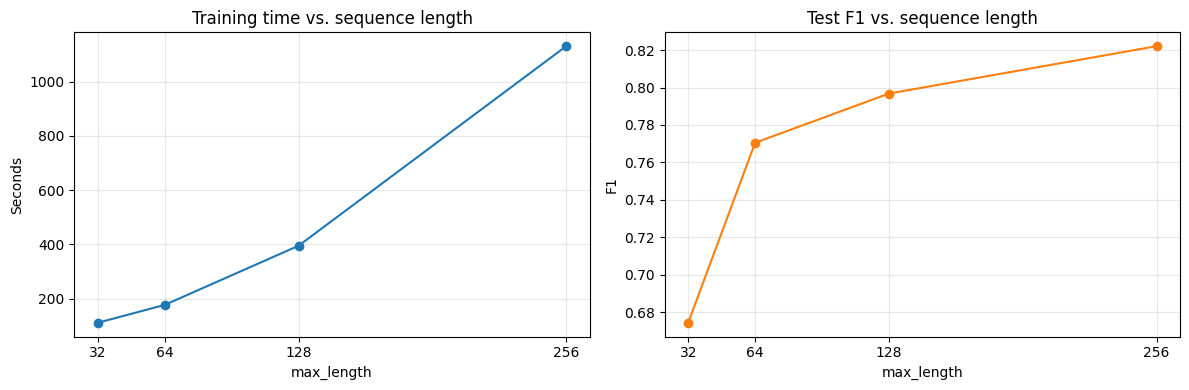

In [ ]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(results_df['max_length'], results_df['Training time (seconds)'], marker='o')
axes[0].set(title='Training time vs. sequence length', xlabel='max_length', ylabel='Seconds')
axes[1].plot(results_df['max_length'], results_df['F1'], marker='o', color='tab:orange')
axes[1].set(title='Test F1 vs. sequence length', xlabel='max_length', ylabel='F1')
for ax in axes:
    ax.set_xticks(LENGTHS); ax.grid(True, alpha=0.3)
fig.tight_layout(); plt.show()
